# 02 - Preprocessing and Feature Engineering

In [1]:
import sys
sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
def save(name):
    plt.tight_layout(); plt.savefig(config.FIGURES_DIR / name, dpi=110); plt.show()
from src.data_preprocessing import load_data, split_data, build_pipeline, build_preprocessor, leakage_check
from src.feature_engineering import FeatureEngineer, ENGINEERED_COLS, FLAG_COLS
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
print(X_train.shape, X_test.shape)
print('Default rate train/test:', round(y_train.mean(), 4), round(y_test.mean(), 4))

(4768, 12) (1192, 12)
Default rate train/test: 0.1995 0.1997


The split is 80/20, stratified, with seed 42. The test set is not touched until the final evaluation.

## Leakage check
Medians used for imputation should come from the training rows only. The table compares what the pipeline learned with what a fit on all data would have learned.

In [2]:
leakage_check(X_train, X_test)

,pipeline_median,train_only_median,train_plus_test_median,uses_train_only
LOAN,16200.000,16200.000,16300.000,True
MORTDUE,65022.000,65022.000,65019.000,True
VALUE,89250.000,89250.000,89235.500,True
YOJ,7.000,7.000,7.000,True
DEROG,0.000,0.000,0.000,True
DELINQ,0.000,0.000,0.000,True
CLAGE,173.495,173.495,173.467,True
NINQ,1.000,1.000,1.000,True
CLNO,20.000,20.000,20.000,True
DEBTINC,34.802,34.802,34.818,True


`pipeline_median` equals `train_only_median` in every row and differs slightly from the train-plus-test values, so the test rows never influence preprocessing. Every fitted step (imputer, clipper, scaler, encoder, SMOTE) lives inside a scikit-learn pipeline, so cross-validation refits them on each training fold.

## Engineered features
| Feature | What it represents | Why it may help |
|---|---|---|
| LTV | Loan / property value | Higher share of the property at stake means more risk |
| MORTGAGE_TO_VALUE | Mortgage owed / property value | Existing leverage on the home |
| TOTAL_LEVERAGE | (Loan + mortgage) / property value | Combined debt burden against the collateral |
| EQUITY | Property value minus mortgage | Cushion available if the borrower struggles |
| NEGATIVE_MARKS, HAS_NEGATIVE_MARKS | DEROG + DELINQ, and whether it is above zero | Combines two related credit-history signals |
| INQUIRIES_PER_LINE | Recent inquiries / (credit lines + 1) | Credit-seeking intensity relative to credit history |
| LOG_LOAN, LOG_MORTDUE, LOG_VALUE | log(1 + amount) | Reduces skew, mainly helps the linear model |
| *_MISSING (8 flags) | Whether the value was absent | Missingness itself predicts default in this data |

The dataset has no income or balance column, so true loan-to-income and credit-utilisation ratios cannot be built. `DEBTINC` is the closest available income-based measure.

In [3]:
fe = FeatureEngineer().transform(X_train)
fe[ENGINEERED_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
LTV,4679.0,0.22,0.17,0.02,0.12,0.17,0.25,2.33
MORTGAGE_TO_VALUE,4280.0,0.71,0.38,0.02,0.62,0.72,0.80,7.16
TOTAL_LEVERAGE,4280.0,0.91,0.43,0.09,0.84,0.90,0.96,9.49
EQUITY,4280.0,31289.46,26594.41,-202437.00,17226.50,26641.50,39741.00,287300.00
NEGATIVE_MARKS,4353.0,0.70,1.51,0.00,0.00,0.00,1.00,17.00
HAS_NEGATIVE_MARKS,4768.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
INQUIRIES_PER_LINE,4354.0,0.09,0.42,0.00,0.00,0.03,0.08,7.00
LOG_LOAN,4768.0,9.67,0.58,7.00,9.31,9.69,10.06,11.41
LOG_MORTDUE,4347.0,11.03,0.64,7.63,10.74,11.08,11.43,12.90
LOG_VALUE,4679.0,11.40,0.50,8.99,11.10,11.40,11.69,13.66


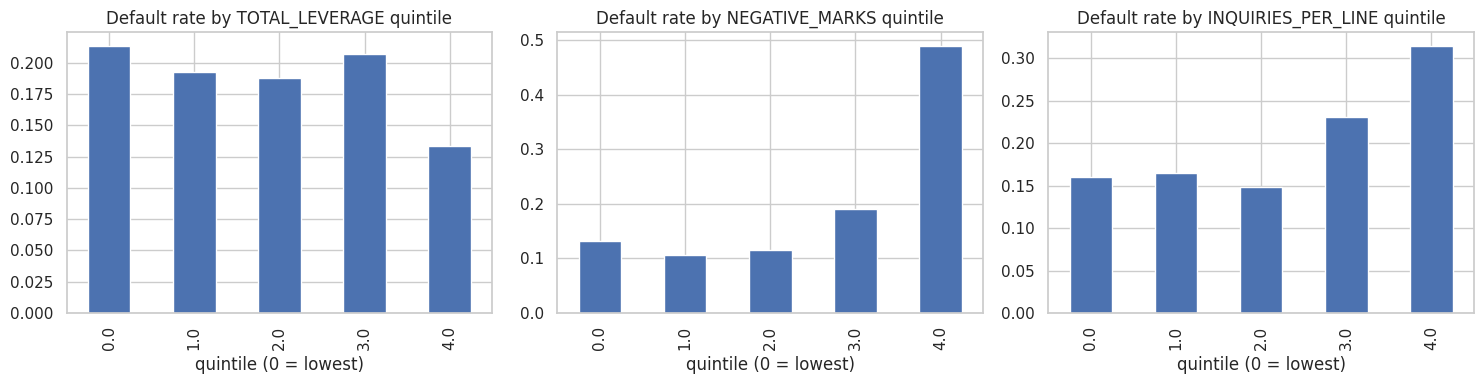

In [4]:
check = fe.assign(BAD=y_train)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['TOTAL_LEVERAGE', 'NEGATIVE_MARKS', 'INQUIRIES_PER_LINE']):
    bins = pd.qcut(check[col].rank(method='first'), 5, labels=False)
    check.groupby(bins).BAD.mean().plot.bar(ax=ax, title=f'Default rate by {col} quintile'); ax.set_xlabel('quintile (0 = lowest)')
save('engineered_feature_check.png')

In [5]:
check.groupby('DEBTINC_MISSING').BAD.agg(['mean', 'size']).round(3)

,mean,size
DEBTINC_MISSING,,
0,0.087,3763
1,0.619,1005


`NEGATIVE_MARKS` and `INQUIRIES_PER_LINE` show a clear rise in default rate in the top quintile. `TOTAL_LEVERAGE` does not: its highest quintile has the lowest default rate, so leverage is not a strong standalone signal in this data (rows with missing property value are excluded from these bins). It is kept because it may still help in combination with other features, and the importance results in notebook 03 show whether it does.

In [6]:
prep = build_preprocessor().fit(FeatureEngineer().transform(X_train))
names = prep.get_feature_names_out()
print(len(names), 'model input columns')
list(names)

38 model input columns


['num__LOAN',
 'num__MORTDUE',
 'num__VALUE',
 'num__YOJ',
 'num__DEROG',
 'num__DELINQ',
 'num__CLAGE',
 'num__NINQ',
 'num__CLNO',
 'num__DEBTINC',
 'num__LTV',
 'num__MORTGAGE_TO_VALUE',
 'num__TOTAL_LEVERAGE',
 'num__EQUITY',
 'num__NEGATIVE_MARKS',
 'num__HAS_NEGATIVE_MARKS',
 'num__INQUIRIES_PER_LINE',
 'num__LOG_LOAN',
 'num__LOG_MORTDUE',
 'num__LOG_VALUE',
 'num__VALUE_MISSING',
 'num__YOJ_MISSING',
 'num__DEROG_MISSING',
 'num__DELINQ_MISSING',
 'num__CLAGE_MISSING',
 'num__NINQ_MISSING',
 'num__CLNO_MISSING',
 'num__DEBTINC_MISSING',
 'cat__REASON_DebtCon',
 'cat__REASON_HomeImp',
 'cat__REASON_Missing',
 'cat__JOB_Mgr',
 'cat__JOB_Missing',
 'cat__JOB_Office',
 'cat__JOB_Other',
 'cat__JOB_ProfExe',
 'cat__JOB_Sales',
 'cat__JOB_Self']